# EDA na Prática

Nas aulas 9 e 10 vimos os quatro princípios da EDA (estrutural, distribucional, relacional e detecção de outliers/anomalias), como tratar dados ausentes e outliers, e como fazer análise descritiva, bivariada e multivariada. Hoje é a hora de **aplicarmos na prática**. Durante a primeira hora da aula, serão apresentadas as técnicas no dataset *Heart Disease* (UCI) e depois **cada aluno** irá aplicar as técnicas no dataset que foi escolhido semana passada.

*Relembrando*: a EDA não é uma linha reta

A EDA costuma ser apresentada como uma sequência de etapas (estrutura → tratamento → descrição → relação), mas na prática ela é **iterativa**: às vezes tratamos um outlier, olhamos a estatística descritiva de novo, e percebemos que precisa voltar atrás. Hoje vamos deixar isso explícito: olhamos a estatística descritiva **antes** de tratar dados ausentes/outliers (pra saber *como* tratar) e **depois** (pra confirmar o efeito do tratamento).

## Como funcionará a atividade

- **Duração:** ~1h40min
- **Formato:** individual
- **Passo 1:** acompanhem a demonstração no dataset Heart Disease.
- **Passo 2:** importem o dataset que vocês escolheram e enviaram anteriormente.
- **Passo 3:** repliquem o mesmo ciclo no dataset escolhido, respondendo às perguntas guiadas.
- **Uso de IA:** permitido, conforme o Plano de Ensino — documentem na seção final.

## Setup de Bibliotecas e Dados

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 5)

COR_NEUTRA = "lightgray"     # convenção: cinza-claro pra tudo que é "pano de fundo" genérico
COR_CONTEXTO = "#e9d4d0"    # rosa-claro pra pano de fundo / classe de referência
COR_DESTAQUE = "#2d223a"    # roxo pra classe de interesse / "o personagem da história"
COR_ALERTA = "tab:red"       # exceção deliberada: outliers/pontos de atenção

palette_gender = {"Female": COR_CONTEXTO, "Male": COR_DESTAQUE}

## Carregando o Dataset

In [ ]:
import kagglehub
import os

# Download latest version
path = kagglehub.dataset_download("willianoliveiragibin/olympics-2024")

print("Path to dataset files:", path)

df = pd.read_csv(os.path.join(path, 'athletes new.csv'))

df.head()

100%|██████████| 352k/352k [00:00<00:00, 10.1MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/willianoliveiragibin/olympics-2024/versions/1


,code,name,name_short,name_tv,gender,function,country_code,country,country_full,nationality,nationality_full,nationality_code,height,weight,disciplines,events,birth_date
0,1535420,VALENCIA Alejandra,VALENCIA A,Alejandra VALENCIA,Female,Athlete,MEX,Mexico,Mexico,Mexico,Mexico,MEX,0,0.0,['Archery'],"[""Women's Individual"", ""Women's Team"", 'Mixed ...",1994-10-17
1,1535429,RUIZ Angela,RUIZ A,Angela RUIZ,Female,Athlete,MEX,Mexico,Mexico,Mexico,Mexico,MEX,0,0.0,['Archery'],"[""Women's Individual"", ""Women's Team""]",2006-07-28
2,1535430,GRANDE Matias,GRANDE M,Matias GRANDE,Male,Athlete,MEX,Mexico,Mexico,Mexico,Mexico,MEX,0,0.0,['Archery'],"[""Men's Individual"", ""Men's Team"", 'Mixed Team']",2004-04-26
3,1536460,ROJAS Carlos,ROJAS C,Carlos ROJAS,Male,Athlete,MEX,Mexico,Mexico,Mexico,Mexico,MEX,0,0.0,['Archery'],"[""Men's Individual"", ""Men's Team""]",2000-01-14
4,1536467,MARTINEZ WING Bruno,MARTINEZ WING B,Bruno MARTINEZ WING,Male,Athlete,MEX,Mexico,Mexico,Mexico,Mexico,MEX,0,0.0,['Archery'],"[""Men's Individual"", ""Men's Team""]",1998-03-08


In [ ]:
import os

# List files in the downloaded Kaggle dataset directory
print(os.listdir(path))

['athletes new.csv']


## 1. Princípio Estrutural

Antes de qualquer análise, precisamos entender a "anatomia" dos dados: quantas linhas e colunas temos, que tipo de dado cada coluna guarda, se há valores faltantes e se há duplicadas.

**Antes de rodar:** o Heart Disease tem 13 variáveis preditoras (idade, sexo, tipo de dor no peito, pressão em repouso, colesterol, entre outras) mais o alvo (`num`, presença/grau de doença cardíaca). Quantas linhas vocês esperam que um dataset clínico como esse tenha — dezenas, centenas ou milhares de pacientes?

### Dimensão e Tipos de Dados

In [ ]:
df.shape

(11115, 17)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11115 entries, 0 to 11114
Data columns (total 17 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   code              11115 non-null  int64  
 1   name              11115 non-null  object 
 2   name_short        11115 non-null  object 
 3   name_tv           11115 non-null  object 
 4   gender            11115 non-null  object 
 5   function          11115 non-null  object 
 6   country_code      11115 non-null  object 
 7   country           11115 non-null  object 
 8   country_full      11115 non-null  object 
 9   nationality       11115 non-null  object 
 10  nationality_full  11115 non-null  object 
 11  nationality_code  11115 non-null  object 
 12  height            11115 non-null  int64  
 13  weight            11099 non-null  float64
 14  disciplines       11115 non-null  object 
 15  events            11115 non-null  object 
 16  birth_date        11115 non-null  object

In [ ]:
df.describe()

,code,height,weight
count,1.111500e+04,11115.000000,11099.000000
mean,1.887426e+06,81.835178,2.213713
std,3.587687e+05,89.504711,13.114771
min,1.532872e+06,0.000000,0.000000
25%,1.888186e+06,0.000000,0.000000
50%,1.918842e+06,0.000000,0.000000
75%,1.948950e+06,177.000000,0.000000
max,9.460001e+06,222.000000,113.000000


### Duplicadas

In [ ]:
df.duplicated().sum()

np.int64(0)

### Renomeando o atributo alvo para facilitar a interpretação

O dataset original registra `num` de 0 (sem doença) a 4 (graus diferentes de doença). Pra hoje, vamos simplificar para uma variável binária, presença ou ausência de doença cardíaca, já que é essa a distinção que vamos usar nas cores ao longo da aula (rosa = sem doença, roxo = com doença).

## 2. Dados Faltantes

In [ ]:
df.isna().sum()

,0
code,0
name,0
name_short,0
name_tv,0
gender,0
function,0
country_code,0
country,0
country_full,0
nationality,0


**Discussao:** Alguma feature tem dados ausentes nos seus dados?

Sim. Esá faltando os dados de peso.



```
# Isto está formatado como código
```

*Resposta*: Sim, esta faltando o peso de 16 atletas.

#### Identificando o mecanismo de dados ausentes

**Pra discutir:** quantas linhas têm as duas colunas ausentes ao mesmo tempo? Isso muda a hipótese sobre o mecanismo de ausência (MCAR/MAR/MNAR), ou parecem eventos independentes?

*Relembrando:*
- MCAR: Mecanismo Aleatório e sem viés
- MAR: Mecanismo Randômico e com viés possível de corrigir
- MNAR: Mecanismo Não Randômico relacionada a própria feature

- *Se supormos que a ausência depende do próprio valor que está faltando*: por exemplo, o paciente não fez o exame porque já se suspeitava (por sinais clínicos observados previamente) que o resultado seria anormal, e o exame extra não seria necessário, isso seria classificado como **MNAR**.
- *Se supormos que a ausência depende de algo externo ao valor em si*: por exemplo, o protocolo de coleta decidiu não solicitar aquele exame, ou o custo do procedimento limitou a coleta, independente do que o resultado provavelmente seria — isso seria classificado como **MAR** (ou até **MCAR**, se a decisão for arbitrária e não sistemática).

Não dá pra decidir entre as duas só olhando os dados — é exatamente o tipo de situação em que testes estatísticos (como o teste de MCAR) e conhecimento de domínio real (falar com quem coletou os dados) resolveriam a dúvida. Na ausência disso, seguimos com a opção mais conservadora na hora de tratar.

**Nota para quando vocês replicarem no dataset de vocês:** se o dataset escolhido tiver *muitas* colunas com *muitos* ausentes, aí sim uma correlação (ou um heatmap) entre os indicadores de ausência passa a fazer sentido. O problema neste caso foi o volume pequeno, não a técnica em si.

In [ ]:
missing_percentage = (df.isna().sum() / len(df)) * 100
print('Porcentagem de valores nulos por coluna:')
display(missing_percentage.round(2))

Porcentagem de valores nulos por coluna:


,0
code,0.00
name,0.00
name_short,0.00
name_tv,0.00
gender,0.00
function,0.00
country_code,0.00
country,0.00
country_full,0.00
nationality,0.00


Após a verficação da porcentagem dos dados faltantes. O padrão do mecanismo de dados ausentes é aleatório. Só está faltando 0,14% dos dados do peso. Sendo assim, vou remover as linhas.

### Transformação da Coluna 'gender' e Definição de Variáveis

In [ ]:
import ast

# Converter 'birth_date' para datetime
df['birth_date'] = pd.to_datetime(df['birth_date'])

# Converter a coluna 'disciplines' de string para lista de strings
df['disciplines'] = df['disciplines'].apply(ast.literal_eval)

In [ ]:
from datetime import datetime

# Calcular a idade a partir da 'birth_date'
current_year = datetime.now().year
df['age'] = current_year - df['birth_date'].dt.year

# Salva o estado ANTES da remoção de zeros, mas DEPOIS da criação da coluna 'age'
df_before_cleaning = df.copy()

# Exibir as primeiras linhas com a nova coluna 'age'
display(df[['name', 'birth_date', 'age']].head())

,name,birth_date,age
0,VALENCIA Alejandra,1994-10-17,32
1,RUIZ Angela,2006-07-28,20
2,GRANDE Matias,2004-04-26,22
3,ROJAS Carlos,2000-01-14,26
4,MARTINEZ WING Bruno,1998-03-08,28


In [ ]:
# Adicionar 'age' à lista de variáveis quantitativas
VARS_QUANT = [
    "height",
    "weight",
    "age"
]

# Re-exibir as estatísticas descritivas com a nova coluna 'age'
desc = df[VARS_QUANT].describe().T
desc["skewness"] = df[VARS_QUANT].skew()
desc["kurtosis"] = df[VARS_QUANT].kurtosis()

(
    desc[["mean", "50%", "std", "min", "max", "skewness", "kurtosis"]]
    .rename(columns={"50%": "median"})
    .round(2)
    .style.format(precision=2)
    .background_gradient(cmap="magma", subset=["skewness", "kurtosis"])
)

,mean,median,std,min,max,skewness,kurtosis
height,81.84,0.00,89.50,0.00,222.00,0.20,-1.93
weight,2.21,0.00,13.11,0.00,113.00,5.92,34.08
age,28.97,28.00,5.41,14.00,72.00,1.11,3.46


#### Tratamento de Valores Zero para 'height' e 'weight'

Ao inspecionar a descrição estatística (`df.describe()`), notamos que as colunas 'height' e 'weight' possuem valores mínimos de 0, com percentis de 25% e 50% também sendo 0. Na maioria dos contextos, altura e peso não podem ser zero para atletas, indicando que esses valores são provavelmente dados ausentes ou inválidos. Portanto, removeremos essas linhas para garantir uma análise mais precisa.

In [ ]:
linhas_antes = df.shape[0]

# Remover linhas onde 'height' ou 'weight' são zero
df = df[(df['height'] > 0) & (df['weight'] > 0)].copy()

linhas_depois = df.shape[0]
print(f"Linhas antes da remoção de zeros: {linhas_antes}")
print(f"Linhas depois da remoção de zeros: {linhas_depois}")
print(f"Linhas removidas: {linhas_antes - linhas_depois}")

Linhas antes da remoção de zeros: 11115
Linhas depois da remoção de zeros: 316
Linhas removidas: 10799


### Dados Faltantes

Após a remoção das linhas com `height` ou `weight` igual a zero na etapa anterior, todos os valores faltantes (que antes existiam apenas em 'weight') foram tratados. Portanto, não há mais dados ausentes no DataFrame para este momento da análise.

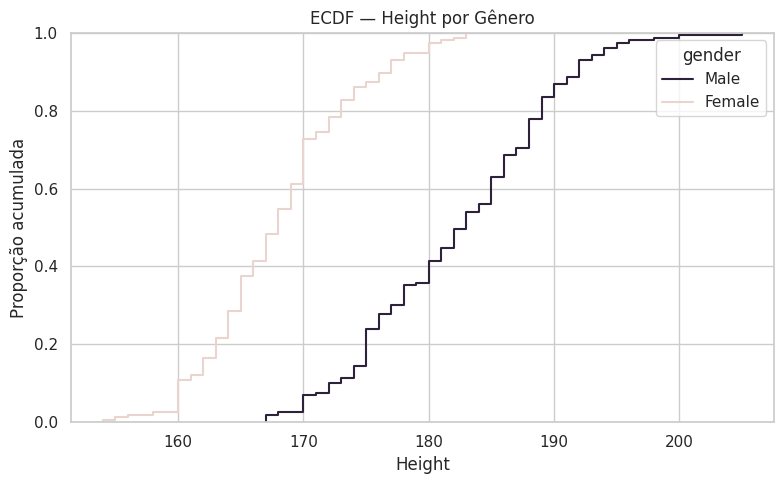

In [ ]:
plt.figure(figsize=(8, 5))
sns.ecdfplot(data=df, x=VARS_QUANT[0], hue="gender",
             palette=palette_gender)
plt.title(f"ECDF — {VARS_QUANT[0].capitalize()} por Gênero")
plt.xlabel(f"{VARS_QUANT[0].capitalize()}")
plt.ylabel("Proporção acumulada")
plt.tight_layout()
plt.show()

## 3. Princípio Distribucional

Ainda com os dados originais (sem tratar ausentes ou outliers), vamos calcular as estatísticas descritivas e olhar as distribuições. Esse retrato "antes" é o que vai *orientar as decisões de tratamento* na próxima seção. Por exemplo, se uma variável for muito assimétrica, faz mais sentido imputar com a mediana do que com a média.

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 316 entries, 7328 to 7644
Data columns (total 18 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   code              316 non-null    int64         
 1   name              316 non-null    object        
 2   name_short        316 non-null    object        
 3   name_tv           316 non-null    object        
 4   gender            316 non-null    object        
 5   function          316 non-null    object        
 6   country_code      316 non-null    object        
 7   country           316 non-null    object        
 8   country_full      316 non-null    object        
 9   nationality       316 non-null    object        
 10  nationality_full  316 non-null    object        
 11  nationality_code  316 non-null    object        
 12  height            316 non-null    int64         
 13  weight            316 non-null    float64       
 14  disciplines       316 non-n

In [ ]:
VARS_QUANT = [
    "height",
    "weight",
    "age"
]

VARS_QUALI = [
    "gender",
    "country_code",
    "disciplines"
    ]

### Tabela descritiva, com assimetria e curtose

desc = df[VARS_QUANT].describe().T
desc["skewness"] = df[VARS_QUANT].skew()
desc["kurtosis"] = df[VARS_QUANT].kurtosis()

(
    desc[["mean", "50%", "std", "min", "max", "skewness", "kurtosis"]]
    .rename(columns={"50%": "median"})
    .round(2)
    .style.format(precision=2)
    .background_gradient(cmap="magma", subset=["skewness", "kurtosis"])
)

,mean,median,std,min,max,skewness,kurtosis
height,175.25,174.50,9.80,154.00,205.00,0.30,-0.67
weight,77.75,76.00,12.95,51.00,113.00,0.24,-0.85
age,28.66,28.00,3.73,22.00,40.00,0.52,-0.14


**Pra discutir:** olhando a tabela, quais variáveis já parecem assimétricas (`skewness` acima de 1) ou com cauda pesada (`kurtosis` maior que 2 em módulo)?

Isso é coerente com o que vocês esperariam fisiologicamente (ex: colesterol e pressão em repouso costumam ter poucos pacientes com valores muito altos, puxando a cauda direita)?

### Distribuições de dados

Onde fizer sentido, comparamos "Sem doença" (rosa) vs. "Com doença" (roxo). Vamos utilizar esta convenção de cor que vamos manter até a análise bivariada.


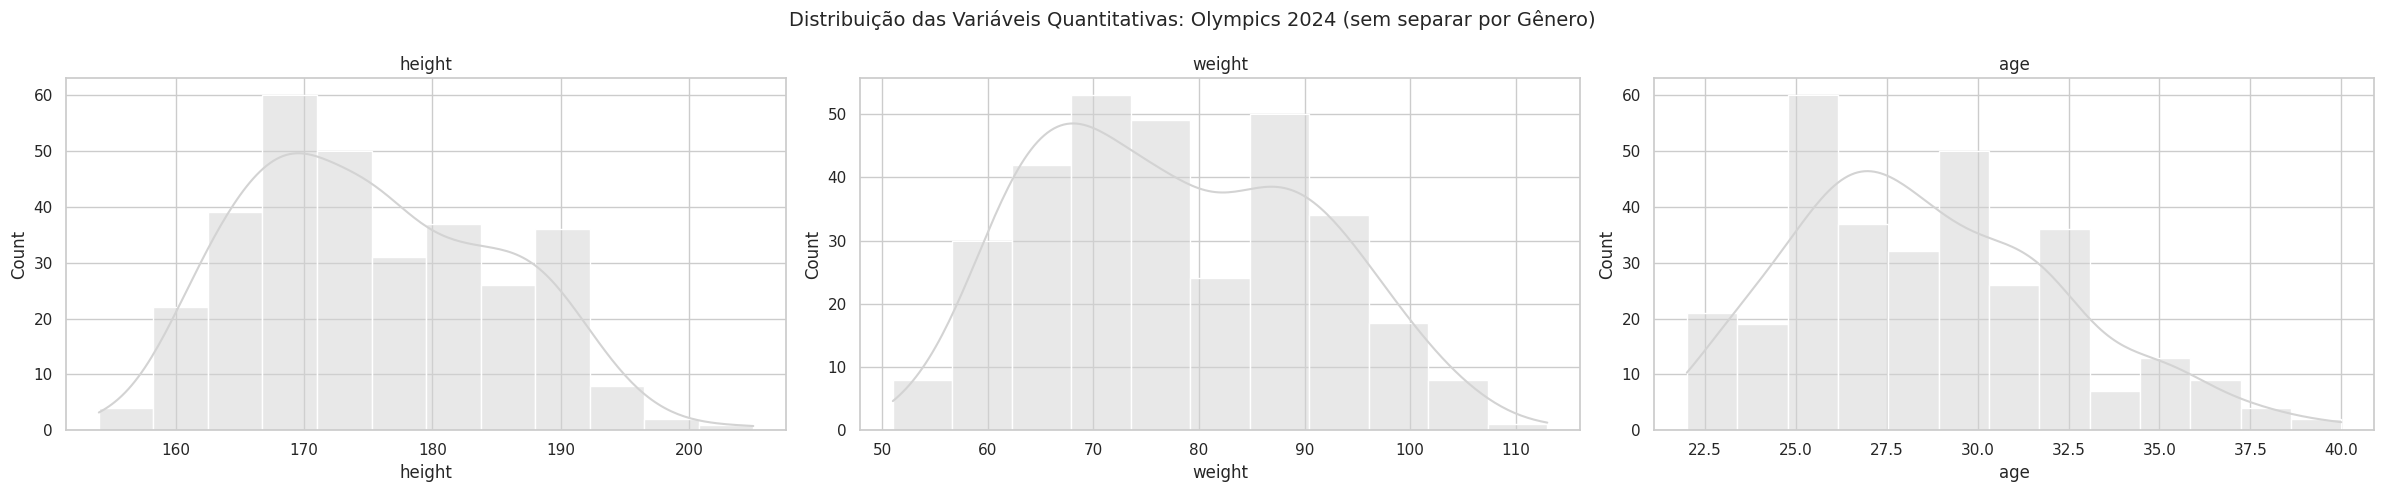

In [ ]:
fig, axes = plt.subplots(1, len(VARS_QUANT), figsize=(8 * len(VARS_QUANT), 5), sharey=False)

if len(VARS_QUANT) == 1:
    axes = [axes] # Ensure axes is iterable even for a single variable

for i, col in enumerate(VARS_QUANT):
    sns.histplot(data=df, x=col, kde=True, color=COR_NEUTRA, ax=axes[i])
    axes[i].set_title(col)

fig.suptitle("Distribuição das Variáveis Quantitativas: Olympics 2024 (sem separar por Gênero)", fontsize=14)
plt.tight_layout()
plt.show()

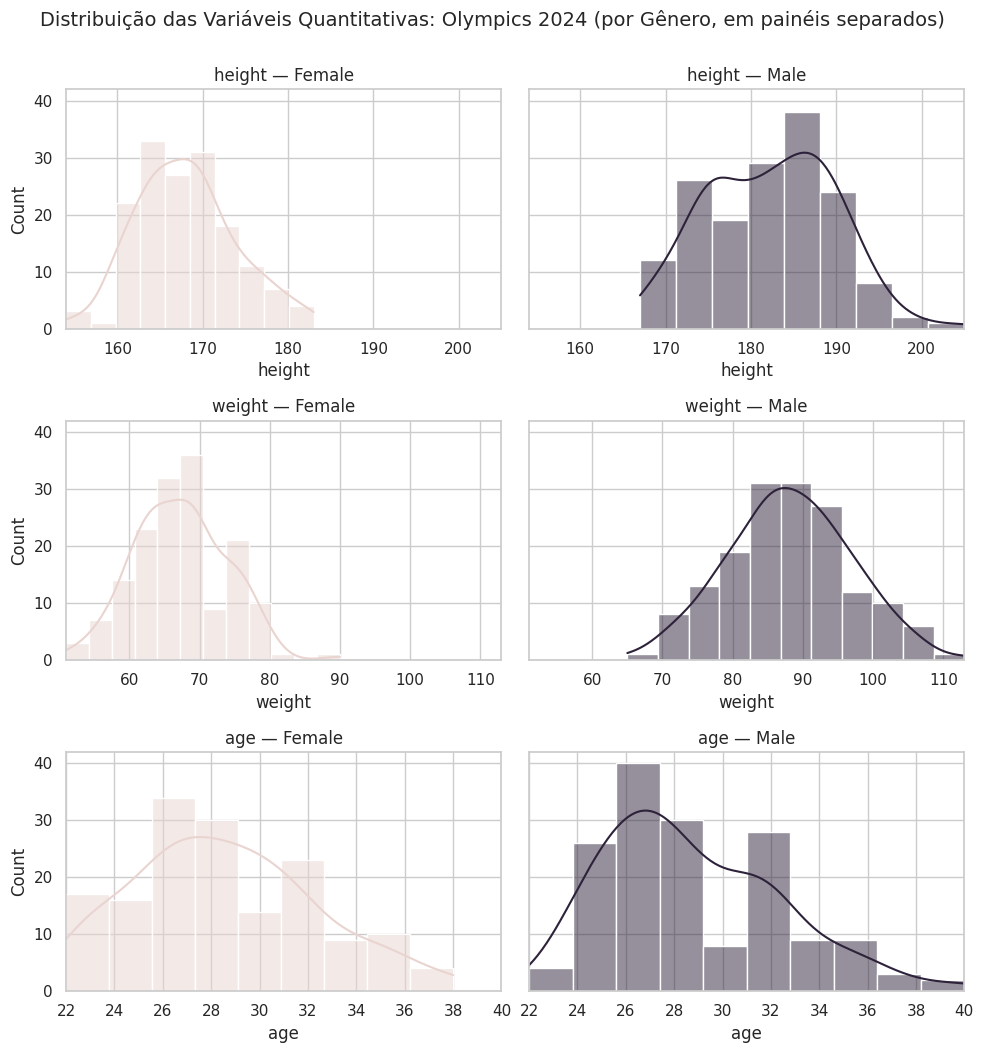

In [ ]:
fig, axes = plt.subplots(len(VARS_QUANT), 2, figsize=(10, 3.5 * len(VARS_QUANT)), sharey=True)

for i, col in enumerate(VARS_QUANT):
    lim = (df[col].min(), df[col].max())
    for j, (classe, cor) in enumerate([("Female", palette_gender["Female"]), ("Male", palette_gender["Male"])]):
        subset = df[df["gender"] == classe]
        sns.histplot(data=subset, x=col, kde=True, color=cor, ax=axes[i, j])
        axes[i, j].set_xlim(lim)
        axes[i, j].set_title(f"{col} — {classe}")

fig.suptitle("Distribuição das Variáveis Quantitativas: Olympics 2024 (por Gênero, em painéis separados)", fontsize=14, y=1.001)
plt.tight_layout()
plt.show()

#### Testes de Aderência em 'height' e 'weight'

Vamos aplicar o teste de Shapiro-Wilk para verificar a normalidade das variáveis 'height' e 'weight', juntamente com o QQ-Plot como visualização de apoio. Testaremos primeiro com 'height'.

Shapiro-Wilk — height: estatística=0.9770, p-valor=6.008e-05
Rejeita H0 (normalidade)? Sim (alpha = 0.05)


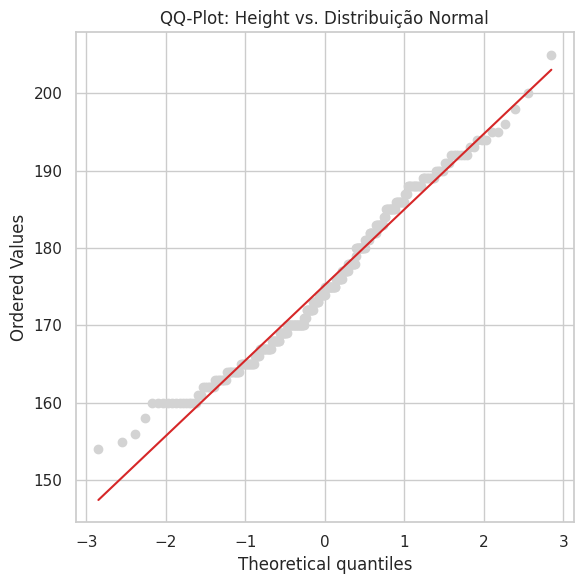

In [ ]:
stat_sw, p_valor_sw = stats.shapiro(df["height"].dropna())
print(f"Shapiro-Wilk — height: estatística={stat_sw:.4f}, p-valor={p_valor_sw:.4g}")
print("Rejeita H0 (normalidade)?", "Sim" if p_valor_sw < 0.05 else "Não", "(alpha = 0.05)")

### QQ-Plot — height

fig, ax = plt.subplots(figsize=(6, 6))
stats.probplot(df["height"].dropna(), dist="norm", plot=ax)
ax.get_lines()[0].set_markerfacecolor(COR_NEUTRA)
ax.get_lines()[0].set_markeredgecolor(COR_NEUTRA)
ax.get_lines()[1].set_color(COR_ALERTA)
ax.set_title("QQ-Plot: Height vs. Distribuição Normal")
plt.tight_layout()
plt.show()

**Como ler:** se os pontos (cinza) seguissem a reta vermelha de perto, a variável seguiria uma normal. Pontos que se afastam da reta nas pontas indicam cauda mais pesada ou mais leve que a normal — coerente com o resultado do Shapiro-Wilk acima.

**Nota: cuidado com duas armadilhas de interpretação**

- **Tamanho da amostra e poder do teste:** é comum achar que "poucos dados" tornam mais fácil rejeitar a normalidade e é o contrário. Amostras **pequenas** têm **menos poder estatístico**, ou seja, tendem a *não* rejeitar mesmo quando os dados realmente não são normais. Já amostras **muito grandes** (milhares de linhas) deixam o teste sensível demais, rejeitando por desvios triviais. Com n≈316 (nem pequeno, nem enorme) e três evidências concordando — skewness alto (se houver), QQ-Plot afastado da reta, e Shapiro-Wilk rejeitando — o resultado é razoavelmente confiável, não um artefato do tamanho da amostra.
- **Como afirmar o resultado:** quando o teste **rejeita** H0 (nosso caso, p < 0.05), a afirmação correta é "temos evidência estatística **contra** a normalidade" que é uma conclusão forte. A frase "não podemos garantir normalidade" cabe no caso oposto: quando o teste **não rejeita** H0, já que a ausência de rejeição nunca prova que os dados são normais, só que não há evidência suficiente contra.

In [ ]:
resultados_shapiro = []
for col in VARS_QUANT:
    stat, p = stats.shapiro(df[col].dropna())
    resultados_shapiro.append({"variavel": col, "estatistica": round(stat, 4),
                                 "p_valor": round(p, 6), "rejeita_normalidade": p < 0.05})

pd.DataFrame(resultados_shapiro).set_index("variavel")

,estatistica,p_valor,rejeita_normalidade
variavel,,,
height,0.9770,0.000060,True
weight,0.9739,0.000017,True
age,0.9694,0.000003,True


**Pra discutir:** Os resultados do Shapiro-Wilk para 'height' e 'weight' indicam normalidade? Isso é consistente com o que vimos nos histogramas e QQ-Plots?

Todos os testes indicam que o p-valor é menor que 0.05, dessa forma sabemos que a hipótese de que essa seria uma distribuição normal é rejeitada.

**ECDF — outra forma de ver a distribuição**

Diferente do histograma, a ECDF não depende de escolher o número de bins: para cada valor no eixo X, a curva mostra a **proporção acumulada** de observações menores ou iguais àquele valor. É especialmente útil pra comparar duas distribuições lado a lado — onde as curvas se distanciam mais é onde a diferença entre os grupos é mais perceptível.

Vamos ilustrar com uma única variável (`weight`), só pra fixar como essa visualização se lê.

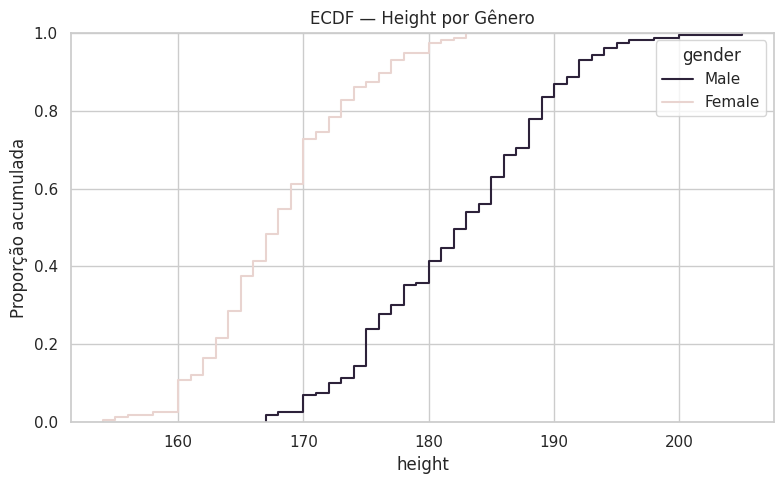

In [ ]:
plt.figure(figsize=(8, 5))
sns.ecdfplot(data=df, x="height", hue="gender",
             palette=palette_gender)
plt.title("ECDF — Height por Gênero")
plt.xlabel("height")
plt.ylabel("Proporção acumulada")
plt.tight_layout()
plt.show()

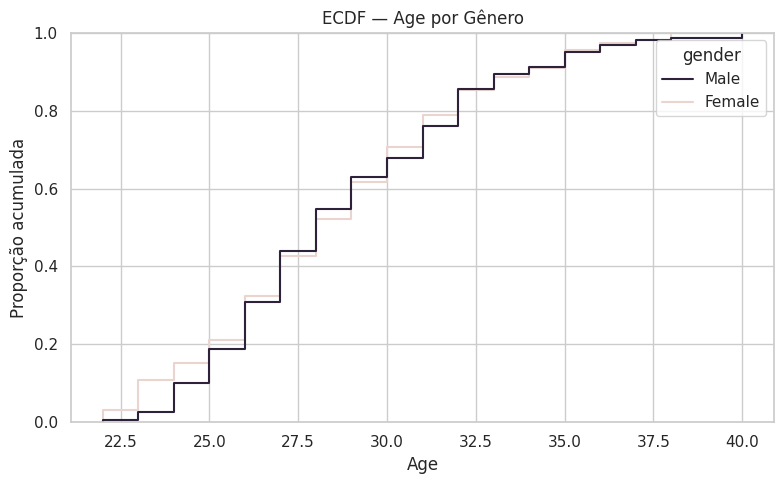

In [ ]:
plt.figure(figsize=(8, 5))
sns.ecdfplot(data=df, x='age', hue='gender',
             palette=palette_gender)
plt.title("ECDF — Age por Gênero")
plt.xlabel("Age")
plt.ylabel("Proporção acumulada")
plt.tight_layout()
plt.show()

**Como ler:** em qualquer ponto do eixo X, a altura da curva diz "que fração dos atletas desse grupo tem peso até aqui". Onde as duas curvas (rosa e roxa) se distanciam mais, ali está a faixa de peso onde os dois grupos mais diferem, sem precisar decidir uma largura de bin como no histograma.

### Métricas de Tendência Central

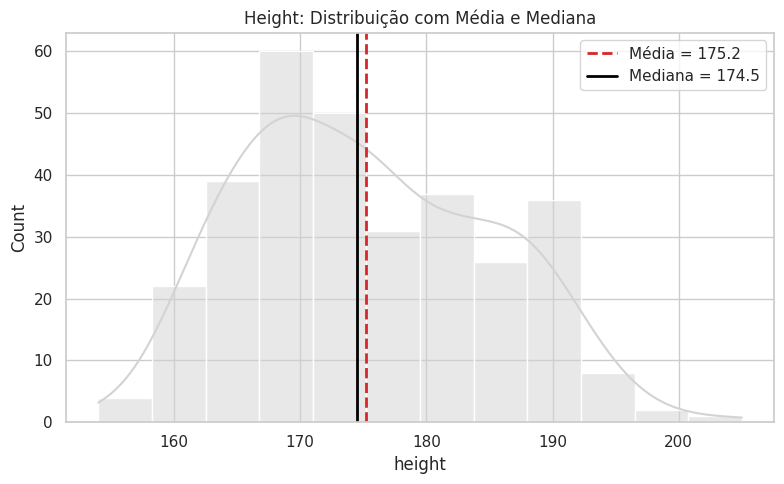

In [ ]:
media_height = df["height"].mean()
mediana_height = df["height"].median()

plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="height", kde=True, color=COR_NEUTRA)
plt.axvline(media_height, color=COR_ALERTA, linestyle="--", linewidth=2, label=f"Média = {media_height:.1f}")
plt.axvline(mediana_height, color="black", linestyle="-", linewidth=2, label=f"Mediana = {mediana_height:.1f}")
plt.title("Height: Distribuição com Média e Mediana")
plt.legend()
plt.tight_layout()
plt.show()

### Dispersão

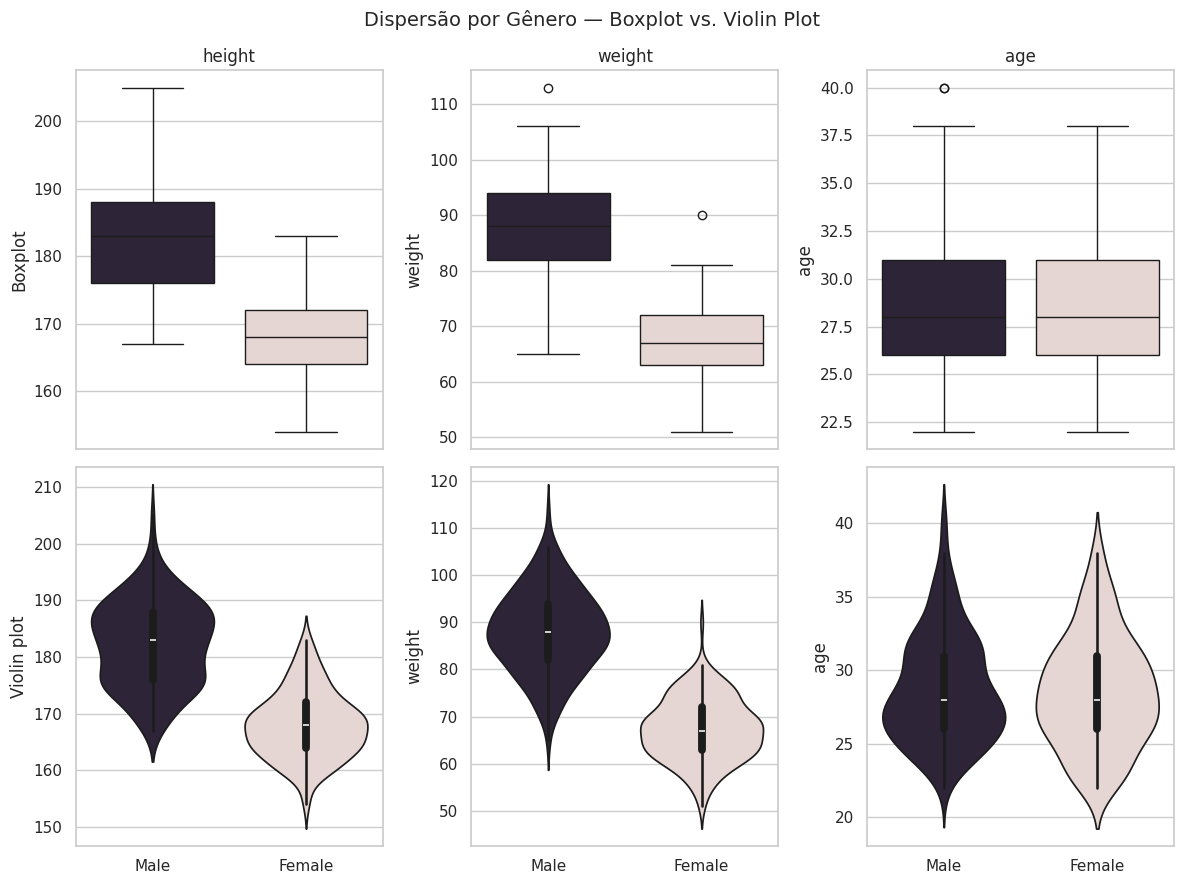

In [ ]:
dispersao = df[VARS_QUANT].agg(["var", "std"]).T
dispersao["IQR"] = df[VARS_QUANT].quantile(0.75) - df[VARS_QUANT].quantile(0.25)
dispersao.round(2)

### Boxplot e violin plot por gênero

fig, axes = plt.subplots(2, len(VARS_QUANT), figsize=(4 * len(VARS_QUANT), 9), sharex="col")

for i, col in enumerate(VARS_QUANT):
    sns.boxplot(data=df, x="gender", y=col, hue="gender",
                palette=palette_gender, legend=False, ax=axes[0, i])
    axes[0, i].set_title(col)
    axes[0, i].set_xlabel("")

    sns.violinplot(data=df, x="gender", y=col, hue="gender",
                    palette=palette_gender, legend=False, ax=axes[1, i])
    axes[1, i].set_xlabel("")

axes[0, 0].set_ylabel("Boxplot")
axes[1, 0].set_ylabel("Violin plot")
fig.suptitle("Dispersão por Gênero — Boxplot vs. Violin Plot", fontsize=14)
plt.tight_layout()
plt.show()

**Pra discutir:** alguma variável mostra uma caixa (IQR) nitidamente mais alta ou mais baixa entre "Normal" e "Cardíaco"? Isso já é um indício — antes mesmo da análise bivariada formal — de que essa variável pode ajudar a diferenciar as duas classes.


Sim, o correlograma confirma as observações anteriores. As distribuições univariadas (histogramas na diagonal) mostram padrões consistentes com os histogramas individuais vistos anteriormente. A forte correlação positiva entre 'height' e 'weight' é claramente visível nos scatter plots (triângulo inferior) e nas representações de círculo (triângulo superior), reforçando o que já havíamos identificado na matriz de correlação. A baixa correlação de 'age' com 'height' e 'weight' também é reafirmada. Não parece haver nenhuma peculiaridade visível que não tenha sido detectada nas análises anteriores, mas o correlograma oferece uma visão consolidada e rica dessas relações de uma só vez.

## 4. Tratamento de Dados Ausentes e Outliers

Agora que já vimos o retrato estatístico "antes" (Seção 3), temos a informação que faltava pra decidir como tratar tanto os dados ausentes (`ca`, `thal`) quanto os outliers das variáveis quantitativas. Depois do tratamento, vamos rodar a estatística descritiva mais uma vez ("depois") pra confirmar o efeito das escolhas e fechar o ciclo iterativo que começamos lá na abertura.


O tratamento de dados ausentes já havia sido feito no início da exploração, pois foi percebido o grande impacto dos dados zerados de peso e altura.

### Detecção de Outliers por IQR

A regra clássica marca como outlier qualquer ponto fora de `[Q1 - 1.5*IQR, Q3 + 1.5*IQR]`.

In [ ]:
def limites_iqr(serie):
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

resumo_outliers = {}
for col in VARS_QUANT:
    lim_inf, lim_sup = limites_iqr(df[col])
    n_outliers = ((df[col] < lim_inf) | (df[col] > lim_sup)).sum()
    resumo_outliers[col] = {
        "limite_inferior": round(lim_inf, 2),
        "limite_superior": round(lim_sup, 2),
        "n_outliers": n_outliers,
    }

pd.DataFrame(resumo_outliers).T

,limite_inferior,limite_superior,n_outliers
height,144.88,205.88,0.0
weight,35.50,119.50,0.0
age,18.50,38.50,2.0


### Visualizando os Outliers

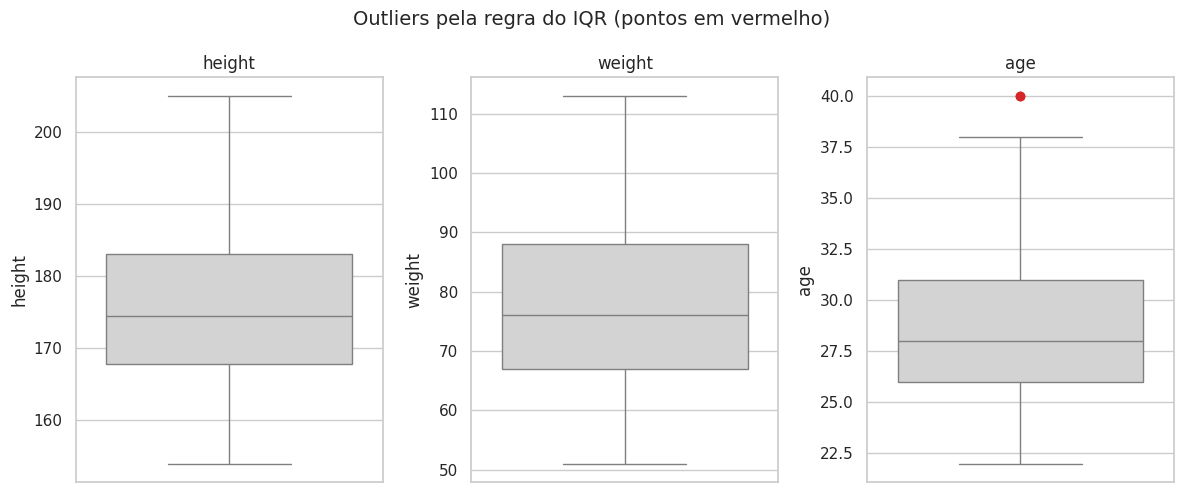

In [ ]:
fig, axes = plt.subplots(1, len(VARS_QUANT), figsize=(4 * len(VARS_QUANT), 5))

for i, col in enumerate(VARS_QUANT):
    sns.boxplot(data=df, y=col, color=COR_NEUTRA,
                flierprops=dict(markerfacecolor=COR_ALERTA, markeredgecolor=COR_ALERTA, marker="o"),
                ax=axes[i])
    axes[i].set_title(col)

fig.suptitle("Outliers pela regra do IQR (pontos em vermelho)", fontsize=14)
plt.tight_layout()
plt.show()

**Pra discutir:** o slide 26 da aula 9 classifica outliers em três tipos, cada um com um tratamento recomendado:

| Tipo | Cenário | O que fazer? |
|---|---|---|
| Estatístico | Legítimo | Manter / Transformar |
| De domínio | Viola regra de negócio ou condições físicas | Investigar! |
| Erros de dados | Falhas | Corrigir se possível / Remover como última opção |

Olhando os outliers encontrados em 'height' e 'weight': eles parecem fisiologicamente plausíveis para atletas (valores extremos mas reais), ou parecem violar algum limite físico conhecido? Isso muda qual das três categorias se aplica — e, consequentemente, se devemos manter, transformar ou remover.

Já havia sido feito o tratamento nos dados de peso e altura, pois havia uma quantidade imensa de dados zerados em peso e altura o que é impossível.

Além disso, depois de fazer o boxplot, foi possível perceber que existe outliers na idade. Entretanto, o dado se mostra plausível, pois há dois atletas perto da faixa dos 40 anos, o que é possével para atletas. Então, não é necessário fazer o tratamento desses dados.

### Decidindo o Tratamento dos Outliers

Diferente dos dados ausentes, aqui **não vamos remover automaticamente**. Pelos valores encontrados para 'height' e 'weight' (dentro de faixas clinicamente plausíveis para atletas, ainda que raras), a classificação mais provável é **"Estatístico"**, outliers legítimos, não erros de coleta. Sendo assim, o tratamento recomendado nesse caso é **manter** (a informação é real e pode ser relevante) ou, se for necessário para alguma técnica estatística específica mais à frente (ex: métodos sensíveis à assimetria), **transformar**.

Vamos manter os valores originais por enquanto, mas ilustrar como ficaria uma transformação logarítmica em 'weight' — útil caso, mais adiante em análises futuras, a assimetria atrapalhe algum teste ou modelo.

In [ ]:
# Esta célula era usada para remover linhas com dados ausentes das colunas 'ca' e 'thal'
# no dataset Heart Disease. Como estamos usando o dataset Olympics 2024, que não possui
# essas colunas, esta etapa não é mais relevante e foi removida.
# O tratamento de dados ausentes e zeros em 'height' e 'weight' já foi feito nas células anteriores.

### Decidindo o Tratamento dos Outliers

Diferente dos ausentes, aqui **não vamos remover automaticamente**. Pelos valores encontrados (dentro de faixas clinicamente plausíveis, ainda que raras), a classificação mais provável é **"Estatístico"**, outliers legítimos, não erros de coleta. Sendo assim, o tratamento recomendado nesse caso é **manter** (a informação é real e pode ser clinicamente relevante — por exemplo, exatamente os pacientes com colesterol mais extremo podem ser os de maior risco) ou, se for necessário para alguma técnica estatística específica mais à frente (ex: métodos sensíveis à assimetria), **transformar**.

Vamos manter os valores originais por enquanto, mas ilustrar como ficaria uma transformação logarítmica em `chol` — útil caso, mais adiante em análises futuras, a assimetria atrapalhe algum teste ou modelo.

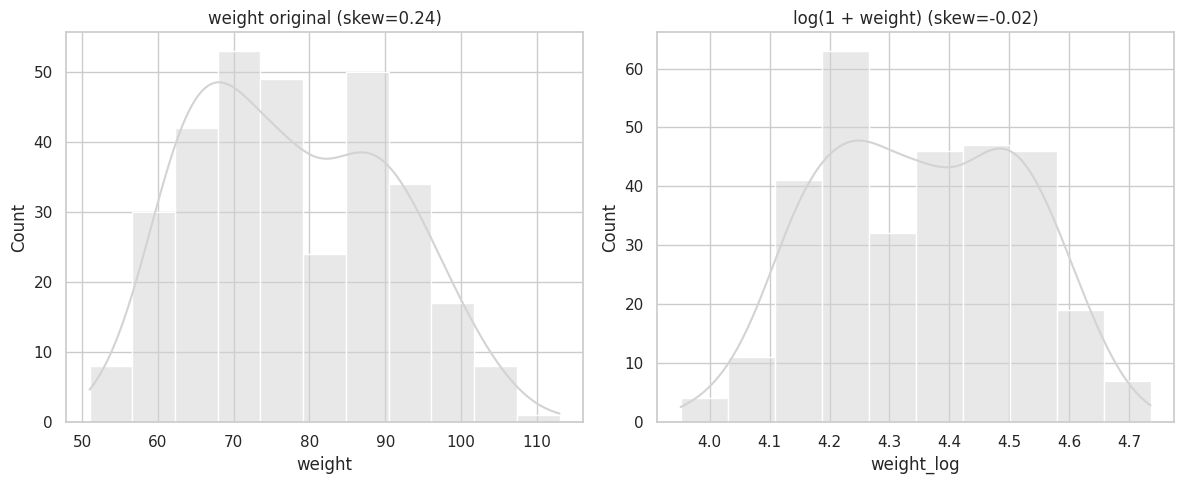

In [ ]:
df["weight_log"] = np.log1p(df["weight"])

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.histplot(data=df, x="weight", kde=True, color=COR_NEUTRA, ax=axes[0])
axes[0].set_title(f"weight original (skew={df['weight'].skew():.2f})")

sns.histplot(data=df, x="weight_log", kde=True, color=COR_NEUTRA, ax=axes[1])
axes[1].set_title(f"log(1 + weight) (skew={df['weight_log'].skew():.2f})")

plt.tight_layout()
plt.show()

**Pra discutir:** a transformação logarítmica reduziu visivelmente a assimetria em 'weight'? Mantivemos `weight_log` só como demonstração, mas não vamos usá-la nas próximas seções. A ideia foi mostrar como opção se fosse o objetivo de, por exemplo, alimentar um teste paramétrico que exige normalidade.


Sim, o correlograma confirma as observações anteriores sobre as distribuições univariadas e as correlações bivariadas de 'height' e 'weight'.



**Nota para quando vocês replicarem no dataset de vocês:** nem todo outlier deve ser removido. Antes de decidir, classifiquem: é um valor estatisticamente raro mas plausível (manter/transformar), viola alguma regra física ou de negócio (investigar antes de decidir), ou é claramente um erro de digitação/coleta (corrigir ou remover)?

## 5. Estatística Descritiva pt 2

Fechando o ciclo iterativo: tratamos os ausentes e decidimos manter os outliers. Agora rodamos a mesma bateria de estatísticas da Seção 3 para comparar diretamente com o "antes".

In [ ]:
desc_antes = df_before_cleaning[VARS_QUANT].describe().T
desc_antes["skewness"] = df_before_cleaning[VARS_QUANT].skew()
desc_antes["kurtosis"] = df_before_cleaning[VARS_QUANT].kurtosis()

desc_depois = df[VARS_QUANT].describe().T
desc_depois["skewness"] = df[VARS_QUANT].skew()
desc_depois["kurtosis"] = df[VARS_QUANT].kurtosis()

(
    desc_depois[["mean", "50%", "std", "min", "max", "skewness", "kurtosis"]]
    .rename(columns={"50%": "median"})
    .round(2)
    .style.format(precision=2)
    .background_gradient(cmap="Blues", subset=["skewness", "kurtosis"])
)

,mean,median,std,min,max,skewness,kurtosis
height,175.25,174.50,9.80,154.00,205.00,0.30,-0.67
weight,77.75,76.00,12.95,51.00,113.00,0.24,-0.85
age,28.66,28.00,3.73,22.00,40.00,0.52,-0.14


In [ ]:
comparacao = pd.DataFrame({
    "skewness_antes": desc_antes["skewness"],
    "skewness_depois": desc_depois["skewness"],
    "kurtosis_antes": desc_antes["kurtosis"],
    "kurtosis_depois": desc_depois["kurtosis"],
})
comparacao["delta_skewness"] = (comparacao["skewness_depois"] - comparacao["skewness_antes"]).round(3)
comparacao["delta_kurtosis"] = (comparacao["kurtosis_depois"] - comparacao["kurtosis_antes"]).round(3)
comparacao.round(3)

,skewness_antes,skewness_depois,kurtosis_antes,kurtosis_depois,delta_skewness,delta_kurtosis
height,0.195,0.299,-1.930,-0.667,0.104,1.263
weight,5.922,0.244,34.078,-0.851,-5.679,-34.929
age,1.105,0.519,3.461,-0.141,-0.586,-3.602


### Comparando "antes" x "depois"

In [ ]:
comparacao = pd.DataFrame({
    "skewness_antes": desc_antes["skewness"],
    "skewness_depois": desc_depois["skewness"],
    "kurtosis_antes": desc_antes["kurtosis"],
    "kurtosis_depois": desc_depois["kurtosis"],
})
comparacao["delta_skewness"] = (comparacao["skewness_depois"] - comparacao["skewness_antes"]).round(3)
comparacao["delta_kurtosis"] = (comparacao["kurtosis_depois"] - comparacao["kurtosis_antes"]).round(3)
comparacao.round(3)

,skewness_antes,skewness_depois,kurtosis_antes,kurtosis_depois,delta_skewness,delta_kurtosis
height,0.195,0.299,-1.930,-0.667,0.104,1.263
weight,5.922,0.244,34.078,-0.851,-5.679,-34.929
age,1.105,0.519,3.461,-0.141,-0.586,-3.602


**Pra discutir:** os valores mudaram muito? Fazia sentido esperar uma diferença grande, considerando que removemos só uma pequena fração das linhas onde 'height' ou 'weight' eram zero? Esse resultado (pouca mudança) é, na verdade, uma confirmação de que o tratamento foi conservador — não um sinal de que ele não fez nada de útil.

**'Height' ainda rejeita normalidade?**

Vamos rodar o mesmo Shapiro-Wilk da Seção 3, agora nos dados tratados (após a remoção das linhas com zero em 'height' e 'weight').

In [ ]:
stat_sw_antes, p_valor_sw_antes = stats.shapiro(df_before_cleaning["height"].dropna())
stat_sw_depois, p_valor_sw_depois = stats.shapiro(df["height"].dropna())
print(f"Shapiro-Wilk (antes)  — height: estatística={stat_sw_antes:.4f}, p-valor={p_valor_sw_antes:.4g}")
print(f"Shapiro-Wilk (depois) — height: estatística={stat_sw_depois:.4f}, p-valor={p_valor_sw_depois:.4g}")

Shapiro-Wilk (antes)  — height: estatística=0.6843, p-valor=2.602e-89
Shapiro-Wilk (depois) — height: estatística=0.9770, p-valor=6.008e-05


/usr/local/lib/python3.13/dist-packages/scipy/stats/_axis_nan_policy.py:579: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 11115.
  res = hypotest_fun_out(*samples, **kwds)


**Visualizando antes x depois, lado a lado**

Vamos sobrepor as distribuições de 'height' e 'weight', comparando a versão original (`df_before_cleaning`) com a tratada (`df`).

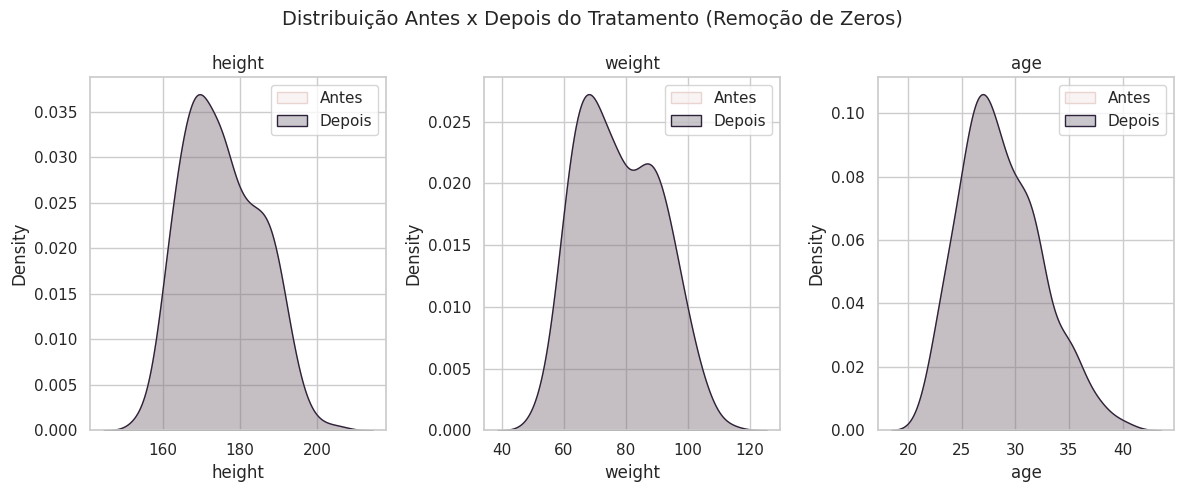

In [ ]:
fig, axes = plt.subplots(1, len(VARS_QUANT), figsize=(4 * len(VARS_QUANT), 5))

for ax, col in zip(axes, VARS_QUANT):
    # Filtrar df_before_cleaning para ter apenas as linhas que foram mantidas em df
    # Isso garante que a comparação seja feita sobre o mesmo conjunto de dados
    # antes e depois da remoção de 0s para height/weight.
    df_before_cleaning_filtered = df_before_cleaning[df_before_cleaning.index.isin(df.index)]

    sns.kdeplot(df_before_cleaning_filtered[col], color=COR_CONTEXTO, fill=True, label="Antes", ax=ax)
    sns.kdeplot(df[col], color=COR_DESTAQUE, fill=True, label="Depois", ax=ax)
    ax.set_title(col)
    ax.legend()

fig.suptitle("Distribuição Antes x Depois do Tratamento (Remoção de Zeros)", fontsize=14)
plt.tight_layout()
plt.show()

**Pra discutir:** as curvas "antes" e "depois" praticamente se sobrepõem? Isso é o esperado aqui, já que removemos poucas linhas e não tocamos nos outliers.

Guardem essa observação: em datasets onde o volume de ausentes/outliers for maior, essa mesma comparação pode mostrar uma diferença bem mais visível e sempre que essa checagem "antes x depois" que confirma (ou não) que o tratamento teve o efeito esperado, em vez de assumir isso às cegas.

## 6. Princípio Relacional

### Análise de Variáveis Qualitativas

Agora focaremos na avaliação de frequência e desbalanceamento das variáveis qualitativas.




#### Frequências absolutas e relativas

In [ ]:
for col in VARS_QUALI:
    freq_abs = df[col].value_counts()
    freq_rel = df[col].value_counts(normalize=True).round(3)
    print(f"\n--- {col} ---")
    print(pd.concat([freq_abs.rename("absoluta"), freq_rel.rename("relativa")], axis=1))


--- gender ---
        absoluta  relativa
gender                    
Male         159     0.503
Female       157     0.497

--- country_code ---
              absoluta  relativa
country_code                    
IRL                 28     0.089
FIJ                 26     0.082
RSA                 26     0.082
JPN                 26     0.082
USA                 26     0.082
FRA                 25     0.079
NZL                 25     0.079
AUS                 25     0.079
GBR                 14     0.044
URU                 14     0.044
ARG                 14     0.044
CHN                 14     0.044
CAN                 14     0.044
BRA                 14     0.044
KEN                 13     0.041
SAM                 12     0.038

--- disciplines ---
                absoluta  relativa
disciplines                       
[Rugby Sevens]       316       1.0


#### Visualizando as frequências

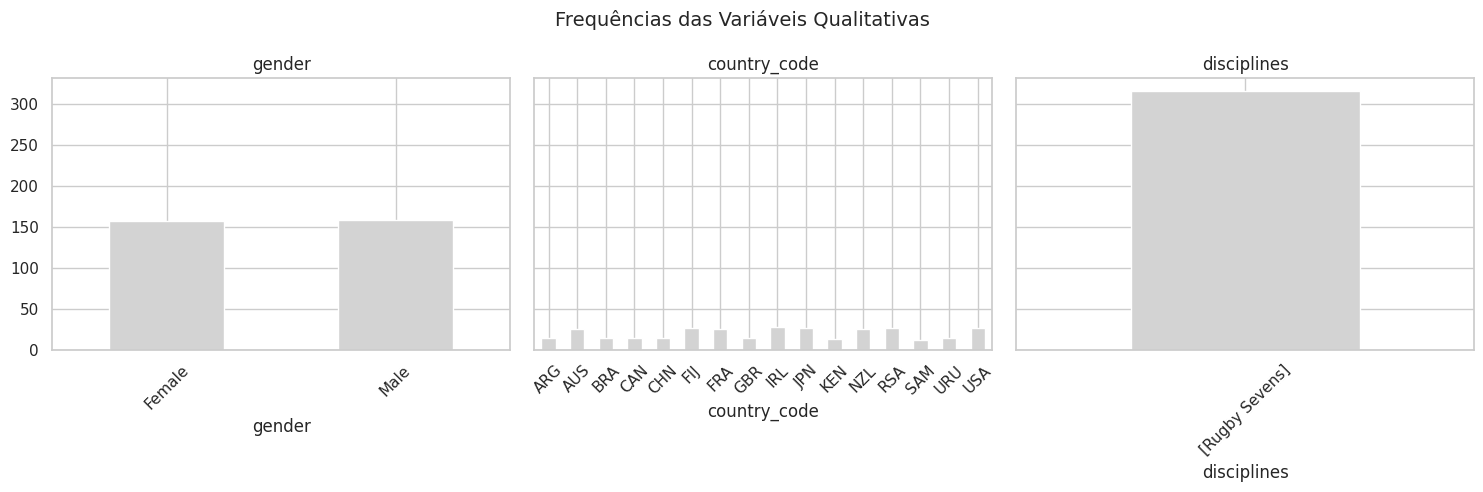

In [ ]:
fig, axes = plt.subplots(1, len(VARS_QUALI), figsize=(5 * len(VARS_QUALI), 5), sharey=True)

if len(VARS_QUALI) == 1: # Handle single qualitative variable case
    axes = [axes]

for i, col in enumerate(VARS_QUALI):
    df[col].value_counts().sort_index().plot(kind="bar", color=COR_NEUTRA, ax=axes[i])
    axes[i].set_title(col)
    axes[i].tick_params(axis="x", rotation=45)

fig.suptitle("Frequências das Variáveis Qualitativas", fontsize=14)
plt.tight_layout()
plt.show()

**Pra discutir:** alguma variável qualitativa está bem desbalanceada (uma categoria dominando quase todas as observações)? Isso pode impactar como vamos interpretar cruzamentos com essa variável mais na frente na análise bivariada.

As variável qualitativa de tipo de esport foi totalmente alterada ao longo da exploração, pois durante as explorações, estavam faltando muitos dados de peso e altura, o que acarretou na retirada das linhas e a acabou restando apenas um único esporte.

#### Desbalanceamento entre Classes

- **Razão de desbalanceamento** — # classe majoritária / # classe minoritária (quanto maior, mais desbalanceado).
- **Entropia de Shannon normalizada** — 1 = perfeitamente balanceado, 0 = uma classe domina tudo.

Vamos aplicar as duas em todas as qualitativas, incluindo o próprio alvo `doenca_cardiaca`.

In [ ]:
from scipy.stats import entropy

def metrica_desbalanceamento(serie):
    contagens = serie.value_counts()
    if contagens.min() == 0: # Handle cases where min count is zero, preventing division by zero
        razao = np.inf
    else:
        razao = contagens.max() / contagens.min()
    props = contagens / contagens.sum()
    n_classes = len(contagens)
    ent_normalizada = entropy(props, base=2) / np.log2(n_classes) if n_classes > 1 else np.nan
    return pd.Series({
        "n_classes": n_classes,
        "razao_desbalanceamento": round(razao, 2),
        "entropia_normalizada": round(ent_normalizada, 3),
    })

vars_para_checar = VARS_QUALI
pd.DataFrame({col: metrica_desbalanceamento(df[col]) for col in vars_para_checar}).T

,n_classes,razao_desbalanceamento,entropia_normalizada
gender,2.0,1.01,1.000
country_code,16.0,2.33,0.982
disciplines,1.0,1.00,NaN


**Pra discutir:** alguma variável está com entropia bem próxima de 0 (bem desbalanceada)? Isso pode impactar como vamos interpretar cruzamentos com essa variável mais na frente na análise bivariada.

Não há variáveis com entropia próxima a zero.

### Análise Bivariada

Agora começamos a avaliar como as variáveis de fato se relacionam entre si e com o alvo 'doença cardíaca'.

#### Quantitativa x Quantitativa - Correlação

Conhecemos três técnicas de correlação principais:
* **Pearson** (linear, sensível a outliers, exige normalidade),
* **Spearman** e **Kendall** (relação monotônica, não exigem normalidade).

Como já vimos que 'height' e 'weight' não passaram no Shapiro-Wilk, Spearman é a escolha mais segura aqui, mas vamos calcular as três para comparar.

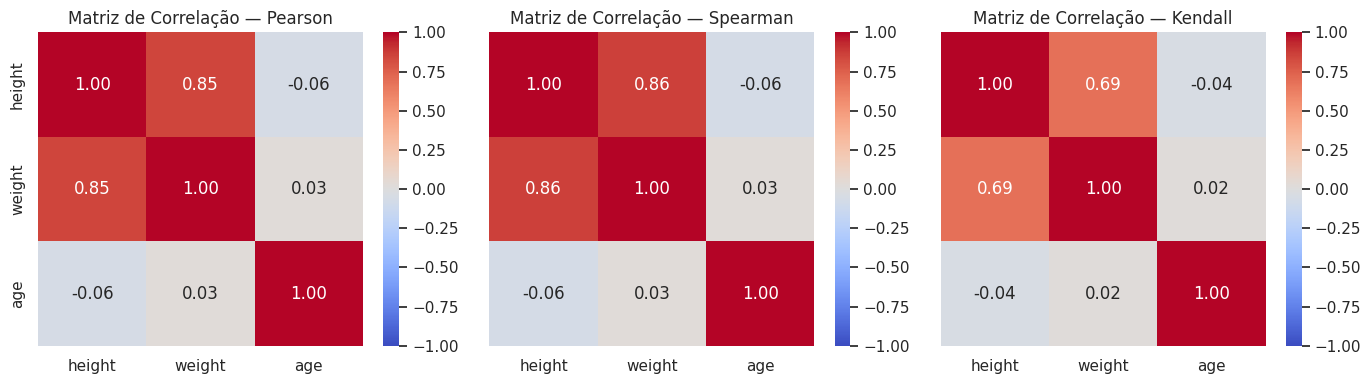

In [ ]:
corr_pearson = df[VARS_QUANT].corr(method="pearson")
corr_spearman = df[VARS_QUANT].corr(method="spearman")
corr_kendall = df[VARS_QUANT].corr(method="kendall")

fig, ax = plt.subplots(1,3,figsize=(14, 4),sharey=True)
sns.heatmap(corr_pearson, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax[0])
ax[0].set_title("Matriz de Correlação — Pearson")
sns.heatmap(corr_spearman, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax[1])
ax[1].set_title("Matriz de Correlação — Spearman")
sns.heatmap(corr_kendall, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax[2])
ax[2].set_title("Matriz de Correlação — Kendall")
plt.tight_layout()
plt.show()

Como os dados do triângulo superior e inferior são simétricos, poderíamos plotar a matriz de correlação da seguinte forma.

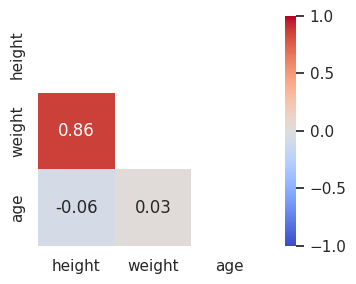

In [ ]:
mask = np.triu(np.ones_like(corr_spearman, dtype=bool))

plt.figure(figsize=(4, 3))
sns.heatmap(corr_spearman, mask=mask, annot=True, cmap="coolwarm", fmt=".2f", square=True, vmin=-1, vmax=1,)
plt.grid(False)

plt.tight_layout()
plt.show()

**Pra discutir:** Pearson e Spearman divergem bastante em algum par de variáveis? Se sim, isso é um sinal de relação não-linear (monotônica, mas não em linha reta) em que Spearman capturaria e Pearson não. No caso de 'height' e 'weight', a correlação deve ser forte e positiva.

Há uma correlação alta positiva entre peso e altura, o que faz sentido já que a tendencia é que quanto mais alta seja uma pessoa, maior será seu peso. Já entre peso e idade, e, entre altura e idade, ambos tem correlação fraca, pois são abaixo de 0.3.

#### Dispersão (scatter) entre duas variáveis quantitativas

Vamos visualizar a relação entre 'height' e 'weight', colorindo os pontos por 'gender'. Essa visualização pode nos dar insights sobre como essas variáveis se distribuem e se relacionam para atletas de diferentes gêneros.

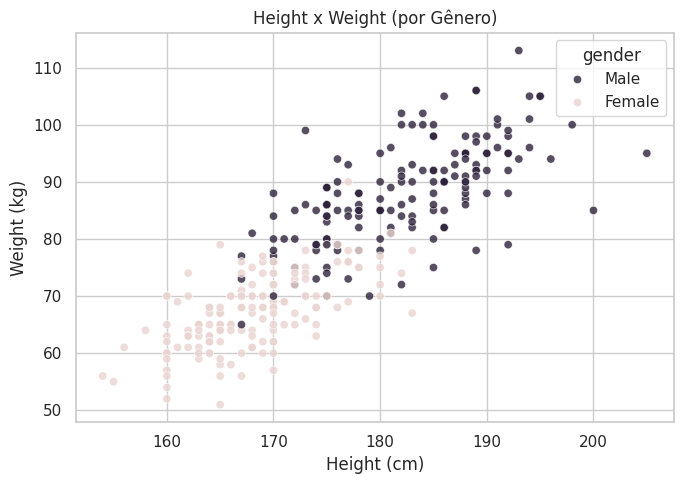

In [ ]:
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df, x="height", y="weight", hue="gender",
                palette=palette_gender, alpha=0.8)
plt.title("Height x Weight (por Gênero)")
plt.xlabel("Height (cm)")
plt.ylabel("Weight (kg)")
plt.tight_layout()
plt.show()

**Pra discutir:** existe uma tendência visível (conforme a altura aumenta, 'weight' tende a aumentar)? As duas classes (gêneros) ocupam regiões diferentes do gráfico, ou estão misturadas? Isso é esperado, dado o dimorfismo sexual em humanos, onde homens geralmente são mais altos e pesados.

Existe uma tendência visual clara entre o peso e altura, algo que já tinha sido visto anteriormente na correlação. Além disso, exite uma separação clara entre homens e mulheres, o que corresponde a uma tendência humana em que homens tendem a ser mais altos e mais pesados que mulheres. Entretanto, é possivível observar que na faixa de 170-180cm exite um encontro dos gêneros, ou seja, existe uma quantidade signicativa dos dois gêneoros coexistindo.

#### Quantitativa x Qualitativa: Comparando Grupos

Na aula passada listamos **T-Test** (2 grupos) e **ANOVA** (3+ grupos) como testes paramétricos pra comparar uma variável quantitativa entre categorias, mas os dois assumem normalidade dentro de cada grupo.

Já vimos que 'height' e 'weight' não passaram no Shapiro-Wilk. Isso significa que, tecnicamente, deveríamos usar os equivalentes **não-paramétricos**: **Mann-Whitney U** no lugar do T-Test, e **Kruskal-Wallis** no lugar da ANOVA. Vamos calcular o Mann-Whitney U para comparar 'height' e 'weight' entre 'Female' e 'Male'.

In [ ]:
resultados_comparacao = []
for col in VARS_QUANT:
    grupo_female = df.loc[df["gender"] == "Female", col]
    grupo_male = df.loc[df["gender"] == "Male", col]

    stat_u, p_u = stats.mannwhitneyu(grupo_female, grupo_male)                 # não-paramétrico

    resultados_comparacao.append({
        "variavel": col,
        "p_valor_mannwhitney": round(p_u, 5),
    })

pd.DataFrame(resultados_comparacao).set_index("variavel")

,p_valor_mannwhitney
variavel,
height,0.0000
weight,0.0000
age,0.6998


**Pra discutir:** o Mann-Whitney U indica uma diferença estatisticamente significativa entre 'Female' e 'Male' para 'height' e 'weight'? Considerando o dimorfismo sexual, é esperado que haja diferenças significativas.

# Exemplo: gender x country_code (usando as 10 maiores nacionalidades)
top_10_countries = df['country_code'].value_counts().nlargest(10).index
df_top_countries = df[df['country_code'].isin(top_10_countries)].copy()

contingencia_gender_country = pd.crosstab(df_top_countries["gender"], df_top_countries["country_code"])

# Verifica se a tabela de contingência tem tamanho suficiente para o teste Qui-Quadrado
if contingencia_gender_country.shape[0] > 1 and contingencia_gender_country.shape[1] > 1:
    chi2, p_chi2, gl, esperado = stats.chi2_contingency(contingencia_gender_country)

    fig, ax = plt.subplots(figsize=(10, 6))
    sns.heatmap(contingencia_gender_country, annot=True, fmt="d", cmap="magma", ax=ax)
    ax.set_title(f"Gender x Country Code (Qui² p-valor={p_chi2:.4g})")
    plt.tight_layout()
    plt.show()
else:
    print("Tabela de contingência muito pequena para realizar o teste Qui-Quadrado.")

# Exemplo: gender x country_code (usando as 10 maiores nacionalidades)
top_10_countries = df['country_code'].value_counts().nlargest(10).index
df_top_countries = df[df['country_code'].isin(top_10_countries)].copy()

contingencia_gender_country = pd.crosstab(df_top_countries["gender"], df_top_countries["country_code"])

# Verifica se a tabela de contingência tem tamanho suficiente para o teste Qui-Quadrado
if contingencia_gender_country.shape[0] > 1 and contingencia_gender_country.shape[1] > 1:
    chi2, p_chi2, gl, esperado = stats.chi2_contingency(contingencia_gender_country)

    fig, ax = plt.subplots(figsize=(10, 6))
    sns.heatmap(contingencia_gender_country, annot=True, fmt="d", cmap="magma", ax=ax)
    ax.set_title(f"Gender x Country Code (Qui² p-valor={p_chi2:.4g})")
    plt.tight_layout()
    plt.show()
else:
    print("Tabela de contingência muito pequena para realizar o teste Qui-Quadrado.")

**Pra discutir:** o p-valor do Qui-Quadrado indica que 'gender' e 'country_code' são independentes, ou há associação estatisticamente significativa entre elas nas 10 maiores nacionalidades? É plausível que a proporção de homens e mulheres em esportes olímpicos varie por país.

In [ ]:
unique_disciplines = df['disciplines'].explode().nunique()

if unique_disciplines <= 1:
    print(f"O atributo 'disciplines' possui apenas {unique_disciplines} disciplina única no DataFrame atual após o pré-processamento. ")
    print("Portanto, não é possível realizar uma análise de associação com 'gender' usando o teste Qui-Quadrado para esta coluna.")
    print("Se houvesse mais de uma disciplina, a análise seria realizada da seguinte forma:")
    print("\n# Exemplo de como a análise seria feita se houvesse mais disciplinas:")
    print("# df_exploded_disciplines = df.explode('disciplines')")
    print("# top_disciplines_for_chi2 = df_exploded_disciplines['disciplines'].value_counts().nlargest(5).index")
    print("# df_filtered_disciplines = df_exploded_disciplines[df_exploded_disciplines['disciplines'].isin(top_disciplines_for_chi2)]")
    print("# contingencia_gender_discipline = pd.crosstab(df_filtered_disciplines['gender'], df_filtered_disciplines['disciplines'])")
    print("# if contingencia_gender_discipline.shape[0] > 1 and contingencia_gender_discipline.shape[1] > 1:")
    print("#     chi2, p_chi2, gl, esperado = stats.chi2_contingency(contingencia_gender_discipline)")
    print("#     fig, ax = plt.subplots(figsize=(10, 6))")
    print("#     sns.heatmap(contingencia_gender_discipline, annot=True, fmt='d', cmap='magma', ax=ax)")
    print("#     ax.set_title(f'Gender x Disciplines (Qui² p-valor={p_chi2:.4g})')")
    print("#     plt.tight_layout()")
    print("#     plt.show()")
    print("# else:")
    print("#     print('Tabela de contingência muito pequena para realizar o teste Qui-Quadrado para disciplinas.')")
elif df['disciplines'].explode().nunique() > 1:
    # If there are multiple disciplines, proceed with the actual Chi-squared test
    df_exploded_disciplines = df.explode('disciplines')
    # Let's take the top 5 disciplines for the chi-squared test for better visualization if many exist
    top_disciplines_for_chi2 = df_exploded_disciplines['disciplines'].value_counts().nlargest(5).index
    df_filtered_disciplines = df_exploded_disciplines[df_exploded_disciplines['disciplines'].isin(top_disciplines_for_chi2)]

    contingencia_gender_discipline = pd.crosstab(df_filtered_disciplines["gender"], df_filtered_disciplines["disciplines"])

    if contingencia_gender_discipline.shape[0] > 1 and contingencia_gender_discipline.shape[1] > 1:
        chi2, p_chi2, gl, esperado = stats.chi2_contingency(contingencia_gender_discipline)

        fig, ax = plt.subplots(figsize=(10, 6))
        sns.heatmap(contingencia_gender_discipline, annot=True, fmt="d", cmap="magma", ax=ax)
        ax.set_title(f"Gender x Disciplines (Qui² p-valor={p_chi2:.4g})")
        plt.tight_layout()
        plt.show()
    else:
        print("Tabela de contingência muito pequena para realizar o teste Qui-Quadrado para disciplinas.")

O atributo 'disciplines' possui apenas 1 disciplina única no DataFrame atual após o pré-processamento. 
Portanto, não é possível realizar uma análise de associação com 'gender' usando o teste Qui-Quadrado para esta coluna.
Se houvesse mais de uma disciplina, a análise seria realizada da seguinte forma:

# Exemplo de como a análise seria feita se houvesse mais disciplinas:
# df_exploded_disciplines = df.explode('disciplines')
# top_disciplines_for_chi2 = df_exploded_disciplines['disciplines'].value_counts().nlargest(5).index
# df_filtered_disciplines = df_exploded_disciplines[df_exploded_disciplines['disciplines'].isin(top_disciplines_for_chi2)]
# contingencia_gender_discipline = pd.crosstab(df_filtered_disciplines['gender'], df_filtered_disciplines['disciplines'])
# if contingencia_gender_discipline.shape[0] > 1 and contingencia_gender_discipline.shape[1] > 1:
#     chi2, p_chi2, gl, esperado = stats.chi2_contingency(contingencia_gender_discipline)
#     fig, ax = plt.subplots(figsize=

**Pra discutir:** no DataFrame atual, o atributo `disciplines` possui apenas uma disciplina única após o pré-processamento, o que impede uma análise de associação com `gender` usando o teste Qui-Quadrado para esta coluna. **É importante notar que, após a remoção dos dados, o dataset agora representa atletas de apenas um esporte olímpico: Rugby Sevens.** Se houvesse variação suficiente nas disciplinas, o p-valor indicaria se `gender` e `disciplines` são independentes ou se há uma associação estatisticamente significativa entre elas.

In [ ]:
# Qui-Quadrado: gender x country_code (10 maiores nacionalidades)
top_10 = df["country_code"].value_counts().nlargest(10).index
df_top = df[df["country_code"].isin(top_10)]
contingencia = pd.crosstab(df_top["country_code"], df_top["gender"])

# Certificar-se de que a contingência tem pelo menos duas linhas/colunas para o qui-quadrado
if contingencia.shape[0] > 1 and contingencia.shape[1] > 1:
    chi2, p_valor, gl, esperado = stats.chi2_contingency(contingencia)

    fig, ax = plt.subplots(figsize=(8, 5))
    sns.heatmap(contingencia, annot=True, fmt="d", cmap="magma", ax=ax)
    ax.set_title(f"country_code x Gender (Qui² p-valor={p_valor:.4g})")
    plt.tight_layout()
    plt.show()
else:
    print("Não é possível calcular Qui-Quadrado para 'country_code' devido ao número insuficiente de categorias ou dados.")

**Pra discutir:** o Qui-Quadrado confirma associação estatisticamente significativa entre 'gender' e 'country_code'? Lembrando que mesmo que a associação seja estatisticamente significativa, isso não diz *por que* ela existe — pode ser um padrão real de participação em esportes por gênero em diferentes países, ou um viés na representação. Um teste estatístico aponta *que* existe associação, não *a causa* dela — essa distinção é o núcleo de qualquer discussão séria de fairness.

#### Outliers bivariados

Vamos visualizar 'height' e 'weight', colorindo os pontos por 'gender'. Isso pode ajudar a identificar combinações incomuns de altura e peso que poderiam ser consideradas outliers em um contexto bivariado.

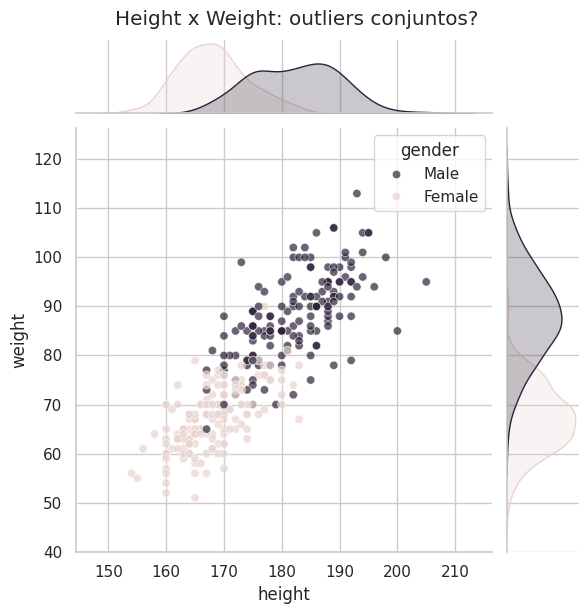

In [ ]:
sns.jointplot(data=df, x="height", y="weight", hue="gender",
              palette=palette_gender, alpha=0.7, height=6)
plt.suptitle("Height x Weight: outliers conjuntos?", y=1.02)
plt.show()

**Pra discutir:** existe algum ponto que não parecia outlier nos histogramas univariados (Seção 3/4), mas que se destaca aqui como uma combinação incomum de 'height' e 'weight'? Isso pode ser um atleta com uma proporção incomum de altura para peso, por exemplo.

#### Análise Multivariada

##### Matriz de Correlação

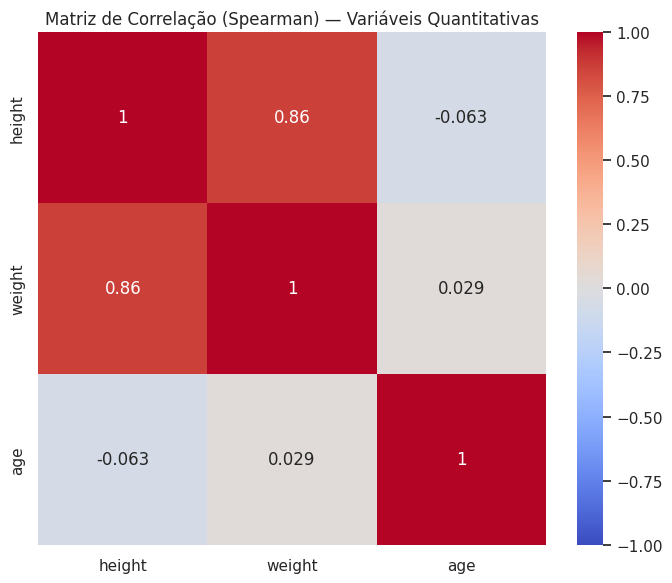

In [ ]:
plt.figure(figsize=(7, 6))
sns.heatmap(df[VARS_QUANT].corr(method="spearman"), annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Matriz de Correlação (Spearman) — Variáveis Quantitativas")
plt.tight_layout()
plt.show()


**Como interpretar:**


*   |r| < 0.3 ~ fraca,
*   0.3 < |r| < 0.7 ~ moderada,
*  |r| > 0.7 ~ forte.

Alguma correlação chama atenção por ser forte o suficiente pra sugerir redundância entre 'height' e 'weight'? Para atletas, é esperado uma correlação positiva e moderada a forte entre essas variáveis.

Como já havia vetrificado anteriormente, há uma forte correlação entre peso e altura.

##### Correlograma

O correlograma é uma visualização mais rica que a matriz de correlação simples, pois combina histogramas de cada variável (na diagonal), scatter plots para pares de variáveis (triângulo inferior) e uma representação visual da correlação (triângulo superior, neste caso com círculos cujo tamanho e cor indicam a força e direção da correlação). É uma ótima ferramenta para entender as distribuições univariadas e as relações bivariadas de uma só vez.

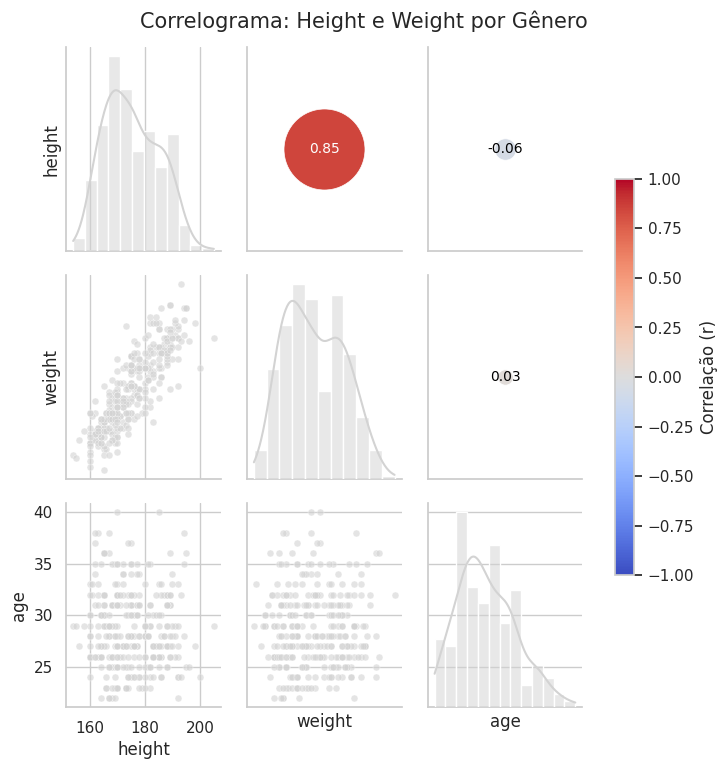

In [ ]:
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize

def circulo_correlacao(x, y, **kwargs):
    r = np.corrcoef(x, y)[0, 1]
    ax = plt.gca()
    ax.scatter(
        [0.5], [0.5],
        s=abs(r) * 4000,          # tamanho proporcional à força da correlação
        c=[r], cmap='coolwarm', vmin=-1, vmax=1,
        transform=ax.transAxes, edgecolor="white", linewidth=0.5,
    )
    ax.annotate(f"{r:.2f}", xy=(0.5, 0.5), xycoords=ax.transAxes,
                ha="center", va="center", fontsize=10,
                color="white" if abs(r) > 0.5 else "black")
    ax.set_xticks([]); ax.set_yticks([])
    ax.grid(False)

g = sns.PairGrid(df[VARS_QUANT], diag_sharey=False)
g.map_lower(sns.scatterplot, color=COR_NEUTRA, alpha=0.6, s=25)
g.map_diag(sns.histplot, color=COR_NEUTRA, kde=True)
g.map_upper(circulo_correlacao)

# barra de cor única, compartilhada (cada subplot superior tem seu próprio scatter)
sm = ScalarMappable(norm=Normalize(-1, 1), cmap='coolwarm')
sm.set_array([])
g.fig.colorbar(sm, ax=g.axes, shrink=0.6, label="Correlação (r)")

g.fig.suptitle("Correlograma: Height e Weight por Gênero", y=1.02, fontsize=15)

plt.show()

**Pra discutir:** o correlograma confirma as observações anteriores sobre as distribuições univariadas e as correlações bivariadas de 'height' e 'weight'? Observamos alguma peculiaridade que não era visível nas análises anteriores?

Essa forma de visualização confirma tudo que já havia sido discutido anteriormente.

## Exportar o dataset tratado

Salva o `df` no estado final da EDA (sem linhas com `height`/`weight` iguais a 0, com as colunas `age` e `weight_log`) em `data/clean/dataset.csv`. É este arquivo que o `app.py` lê.

> Rode o notebook **do início ao fim** antes desta seção, para que o `df` esteja no estado final.

In [ ]:
# Define a pasta de destino (funciona rodando de notebooks/ ou da raiz do projeto)
from pathlib import Path

RAIZ = Path("..") if Path("../data").exists() else Path(".")
PASTA_CLEAN = RAIZ / "data" / "clean"
PASTA_CLEAN.mkdir(parents=True, exist_ok=True)

In [ ]:
df.to_csv(PASTA_CLEAN / "dataset.csv", index=False)

print(f"Clean salvo em {PASTA_CLEAN / 'dataset.csv'} — {df.shape[0]} linhas x {df.shape[1]} colunas")
print(f"Linhas removidas no tratamento: {df_before_cleaning.shape[0] - df.shape[0]}")

## Declaração de udo de IA

A inteligência artificial, especificamente o Gemini integrado, foi utilizada como ferramenta de apoio durante o desenvolvimento deste notebook. Seu uso incluiu a geração e adaptação de código para visualizações, a verificação de abordagens para análises estatísticas e a complementação de explicações e discussões sobre os resultados obtidos.